# Semana 8 — Implementación y comparación de algoritmos de clasificación
**CADI: Introducción a Machine Learning | Universidad de Cundinamarca**

## Objetivo
Implementar y comparar cinco algoritmos de clasificación sobre el conjunto **Breast Cancer Wisconsin Diagnostic**, usando la misma partición de entrenamiento y prueba. Se evaluarán Accuracy, Precision, Recall, F1-score y matrices de confusión para seleccionar un modelo con criterios acordes al problema.

> **Alcance académico:** este ejercicio no constituye una herramienta clínica ni debe utilizarse para diagnosticar o tomar decisiones médicas.

## 1. Importación de librerías
Se importan las herramientas para manipular datos, dividir las observaciones, entrenar los modelos y calcular las métricas. Se utilizará `random_state=42` para que la división y el árbol/forest sean reproducibles.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)

pd.set_option("display.max_columns", 40)

## 2. Carga del conjunto de datos
Scikit-learn incluye el conjunto de datos. `X` contiene las 30 mediciones numéricas y `y` será la variable objetivo binaria. La guía define **1 = maligno** y **0 = benigno**; por eso se invierte la codificación original con `(data.target == 0)`.

In [2]:
data = load_breast_cancer(as_frame=True)
X = data.data.copy()
y = (data.target == 0).astype(int)  # 1 = maligno; 0 = benigno

print(f"Observaciones: {X.shape[0]}")
print(f"Variables de entrada: {X.shape[1]}")
print(f"Valores faltantes en X: {X.isna().sum().sum()}")
print("\\nDistribución de la variable objetivo:")
print(y.map({0: "Benigno", 1: "Maligno"}).value_counts())

Observaciones: 569
Variables de entrada: 30
Valores faltantes en X: 0
\nDistribución de la variable objetivo:
target
Benigno    357
Maligno    212
Name: count, dtype: int64


## 3. Exploración inicial
La distribución de clases permite evaluar si existe desbalance. También se visualizan las cantidades por diagnóstico. En este conjunto hay 569 observaciones y 30 variables de entrada; la clase benigna es más frecuente que la maligna, por lo que no conviene evaluar los modelos solo con Accuracy.

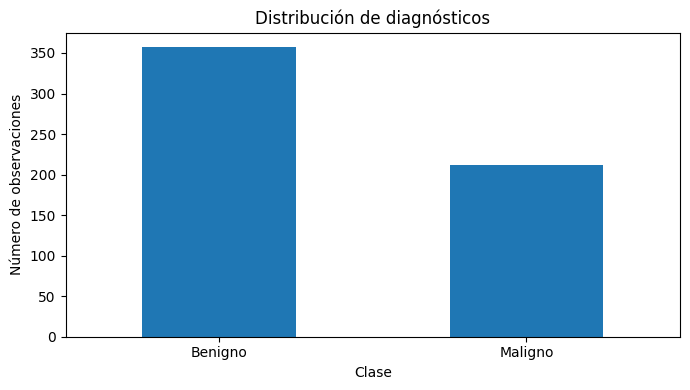

,Tipo de dato,Valores faltantes,Media,Desviación estándar
mean radius,float64,0,14.127292,3.524049
mean texture,float64,0,19.289649,4.301036
mean perimeter,float64,0,91.969033,24.298981
mean area,float64,0,654.889104,351.914129
mean smoothness,float64,0,0.096360,0.014064
mean compactness,float64,0,0.104341,0.052813
mean concavity,float64,0,0.088799,0.079720
mean concave points,float64,0,0.048919,0.038803
mean symmetry,float64,0,0.181162,0.027414
mean fractal dimension,float64,0,0.062798,0.007060


In [3]:
conteo = y.map({0: "Benigno", 1: "Maligno"}).value_counts().reindex(["Benigno", "Maligno"])
ax = conteo.plot(kind="bar", rot=0, figsize=(7, 4))
ax.set_title("Distribución de diagnósticos")
ax.set_xlabel("Clase")
ax.set_ylabel("Número de observaciones")
plt.tight_layout()
plt.show()

display(pd.DataFrame({
    "Tipo de dato": X.dtypes.astype(str),
    "Valores faltantes": X.isna().sum(),
    "Media": X.mean(),
    "Desviación estándar": X.std()
}).head(10))

## 4. Variables de entrada y variable objetivo
- **Variables de entrada (`X`):** las 30 características numéricas calculadas a partir de imágenes digitalizadas de muestras.
- **Variable objetivo (`y`):** diagnóstico codificado como 0 (benigno) y 1 (maligno).

Definir la clase positiva como maligna es importante porque Precision, Recall y F1-score se calcularán para detectar esa clase. En este contexto académico, un falso negativo corresponde a un caso maligno clasificado como benigno.

In [4]:
print("Forma de X:", X.shape)
print("Forma de y:", y.shape)
print("Clases de y:", sorted(y.unique()))

Forma de X: (569, 30)
Forma de y: (569,)
Clases de y: [np.int64(0), np.int64(1)]


## 5. División entrenamiento/prueba
Se usa una única división 80/20 para todos los algoritmos. `stratify=y` conserva aproximadamente la proporción de diagnósticos en ambos subconjuntos. El conjunto de prueba no se modifica entre modelos.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Entrenamiento: {X_train.shape[0]} observaciones")
print(f"Prueba: {X_test.shape[0]} observaciones")
print("\\nProporción de malignos en entrenamiento:", round(y_train.mean(), 3))
print("Proporción de malignos en prueba:", round(y_test.mean(), 3))

Entrenamiento: 455 observaciones
Prueba: 114 observaciones
\nProporción de malignos en entrenamiento: 0.374
Proporción de malignos en prueba: 0.368


## 6. Configuración de los cinco clasificadores
Se mantienen los parámetros indicados en la guía. SVM y K-NN se implementan con `Pipeline` para que `StandardScaler` estandarice las variables antes de entrenar y predecir. Los árboles y GaussianNB se usan sin escalamiento en esta práctica.

In [6]:
modelos = {
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "SVM": make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", C=1.0, gamma="scale")
    ),
    "K-NN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),
    "Naive Bayes": GaussianNB()
}

## 7. Función común de evaluación
La función entrena cada modelo con los mismos datos, predice sobre `X_test` y calcula las cuatro métricas. La matriz de confusión se interpreta con el orden de clases `[0, 1]`: filas = clase real y columnas = clase predicha. Por tanto, la celda inferior izquierda representa los falsos negativos de la clase maligna.

In [7]:
def evaluar_modelo(nombre, modelo, X_train, y_train, X_test, y_test):
    modelo.fit(X_train, y_train)
    pred = modelo.predict(X_test)

    resultado = {
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-score": f1_score(y_test, pred, zero_division=0)
    }
    return resultado, pred

resultados = []
predicciones = {}
for nombre, modelo in modelos.items():
    resultado, pred = evaluar_modelo(
        nombre, modelo, X_train, y_train, X_test, y_test
    )
    resultados.append(resultado)
    predicciones[nombre] = pred

resultados_df = pd.DataFrame(resultados).set_index("Modelo")
display(resultados_df.style.format("{:.3f}"))

,Accuracy,Precision,Recall,F1-score
Modelo,,,,
Decision Tree,0.912,0.944,0.810,0.872
Random Forest,0.974,1.000,0.929,0.963
SVM,0.974,1.000,0.929,0.963
K-NN,0.956,0.974,0.905,0.938
Naive Bayes,0.939,1.000,0.833,0.909


## 8. Decision Tree — Árbol de decisión
Un árbol realiza divisiones sucesivas de los datos según las características. Limitar `max_depth=4` reduce la complejidad y facilita explicar las reglas, aunque un árbol poco profundo puede dejar de captar patrones relevantes.

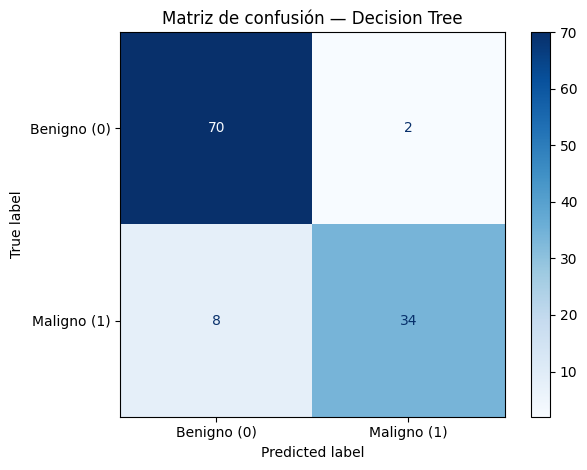

              precision    recall  f1-score   support

     Benigno       0.90      0.97      0.93        72
     Maligno       0.94      0.81      0.87        42

    accuracy                           0.91       114
   macro avg       0.92      0.89      0.90       114
weighted avg       0.91      0.91      0.91       114

Falsos negativos (maligno predicho benigno): 8


In [8]:
nombre = "Decision Tree"
cm = confusion_matrix(y_test, predicciones[nombre], labels=[0, 1])
disp = ConfusionMatrixDisplay(cm, display_labels=["Benigno (0)", "Maligno (1)"])
disp.plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusión — Decision Tree")
plt.tight_layout()
plt.show()
print(classification_report(y_test, predicciones[nombre],
                            target_names=["Benigno", "Maligno"], zero_division=0))
print("Falsos negativos (maligno predicho benigno):", cm[1, 0])

## 9. Random Forest
Random Forest combina múltiples árboles entrenados con variaciones de los datos y de las características. La combinación suele reducir la variabilidad de un árbol individual y mejorar la capacidad de generalización, aunque el conjunto es menos sencillo de explicar como una única regla.

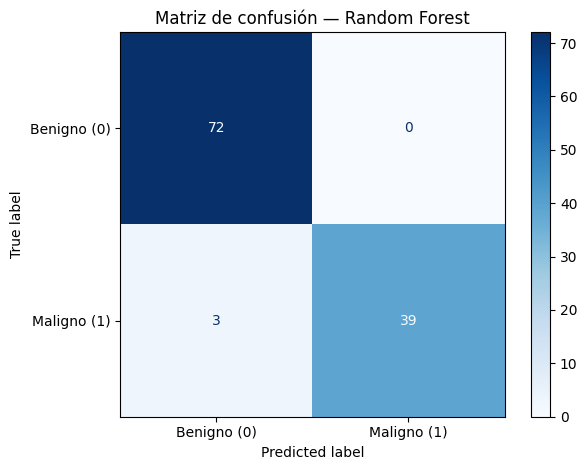

              precision    recall  f1-score   support

     Benigno       0.96      1.00      0.98        72
     Maligno       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114

Falsos negativos (maligno predicho benigno): 3


In [9]:
nombre = "Random Forest"
cm = confusion_matrix(y_test, predicciones[nombre], labels=[0, 1])
disp = ConfusionMatrixDisplay(cm, display_labels=["Benigno (0)", "Maligno (1)"])
disp.plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusión — Random Forest")
plt.tight_layout()
plt.show()
print(classification_report(y_test, predicciones[nombre],
                            target_names=["Benigno", "Maligno"], zero_division=0))
print("Falsos negativos (maligno predicho benigno):", cm[1, 0])

## 10. Support Vector Machine (SVM)
SVM busca una frontera que separe las clases; con el kernel RBF puede representar relaciones no lineales. La estandarización es importante porque las variables tienen escalas distintas y pueden afectar la frontera aprendida.

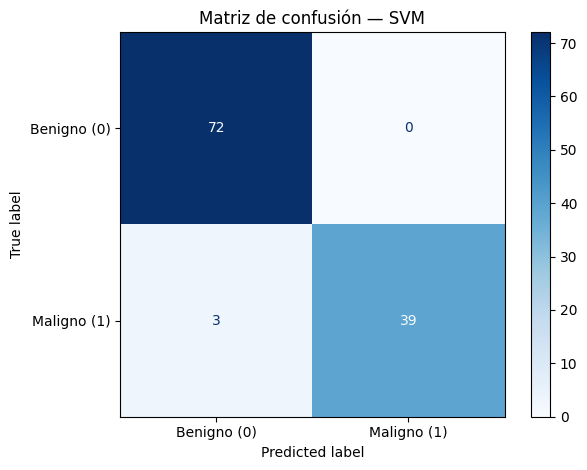

              precision    recall  f1-score   support

     Benigno       0.96      1.00      0.98        72
     Maligno       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114

Falsos negativos (maligno predicho benigno): 3


In [10]:
nombre = "SVM"
cm = confusion_matrix(y_test, predicciones[nombre], labels=[0, 1])
disp = ConfusionMatrixDisplay(cm, display_labels=["Benigno (0)", "Maligno (1)"])
disp.plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusión — SVM")
plt.tight_layout()
plt.show()
print(classification_report(y_test, predicciones[nombre],
                            target_names=["Benigno", "Maligno"], zero_division=0))
print("Falsos negativos (maligno predicho benigno):", cm[1, 0])

## 11. K-Nearest Neighbors (K-NN)
K-NN clasifica cada observación según la clase mayoritaria entre sus cinco vecinos más cercanos (`k=5`). Como depende de distancias, el escalamiento evita que las variables con valores numéricos grandes dominen el cálculo.

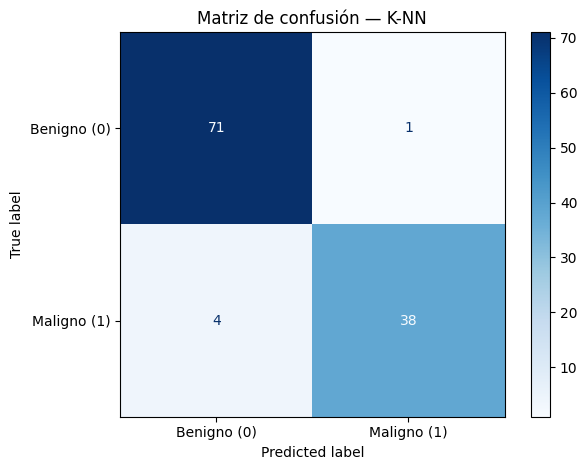

              precision    recall  f1-score   support

     Benigno       0.95      0.99      0.97        72
     Maligno       0.97      0.90      0.94        42

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114

Falsos negativos (maligno predicho benigno): 4


In [11]:
nombre = "K-NN"
cm = confusion_matrix(y_test, predicciones[nombre], labels=[0, 1])
disp = ConfusionMatrixDisplay(cm, display_labels=["Benigno (0)", "Maligno (1)"])
disp.plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusión — K-NN")
plt.tight_layout()
plt.show()
print(classification_report(y_test, predicciones[nombre],
                            target_names=["Benigno", "Maligno"], zero_division=0))
print("Falsos negativos (maligno predicho benigno):", cm[1, 0])

## 12. Naive Bayes (GaussianNB)
GaussianNB estima la probabilidad de cada clase a partir de las características y supone que estas son condicionalmente independientes dada la clase, además de modelar su distribución como gaussiana. Es rápido, pero el supuesto de independencia puede ser poco realista cuando las mediciones están relacionadas.

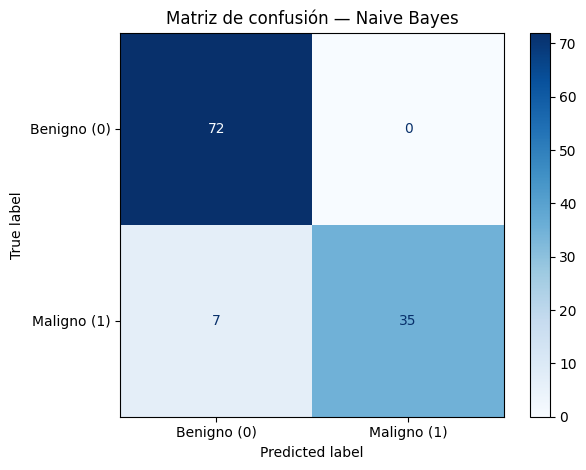

              precision    recall  f1-score   support

     Benigno       0.91      1.00      0.95        72
     Maligno       1.00      0.83      0.91        42

    accuracy                           0.94       114
   macro avg       0.96      0.92      0.93       114
weighted avg       0.94      0.94      0.94       114

Falsos negativos (maligno predicho benigno): 7


In [12]:
nombre = "Naive Bayes"
cm = confusion_matrix(y_test, predicciones[nombre], labels=[0, 1])
disp = ConfusionMatrixDisplay(cm, display_labels=["Benigno (0)", "Maligno (1)"])
disp.plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusión — Naive Bayes")
plt.tight_layout()
plt.show()
print(classification_report(y_test, predicciones[nombre],
                            target_names=["Benigno", "Maligno"], zero_division=0))
print("Falsos negativos (maligno predicho benigno):", cm[1, 0])

## 13. Comparación gráfica de métricas
Las métricas se presentan juntas para identificar fortalezas y compromisos. Accuracy resume la proporción total de aciertos; Precision mide qué proporción de las predicciones malignas fue correcta; Recall mide qué proporción de los casos malignos reales fue detectada; F1-score combina Precision y Recall.

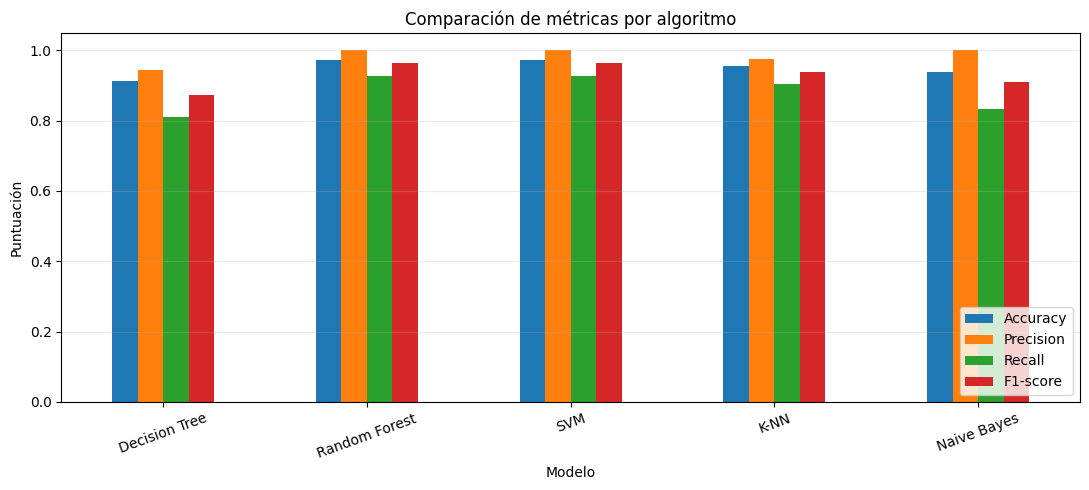

In [13]:
ax = resultados_df.plot(kind="bar", figsize=(11, 5), ylim=(0, 1.05), rot=20)
ax.set_title("Comparación de métricas por algoritmo")
ax.set_ylabel("Puntuación")
ax.set_xlabel("Modelo")
ax.legend(loc="lower right")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 14. Tabla comparativa y análisis de errores
Además de comparar las métricas, se cuentan los falsos negativos. Como la clase positiva es “maligno”, minimizar este error es relevante para el planteamiento del caso. No obstante, el desempeño en una sola partición no garantiza resultados similares en otros datos.

In [14]:
resumen = resultados_df.copy()
resumen["Falsos negativos"] = [
    confusion_matrix(y_test, predicciones[n], labels=[0, 1])[1, 0]
    for n in resumen.index
]
display(resumen.sort_values(["Recall", "F1-score"], ascending=False).style.format({
    "Accuracy": "{:.3f}", "Precision": "{:.3f}",
    "Recall": "{:.3f}", "F1-score": "{:.3f}"
}))

,Accuracy,Precision,Recall,F1-score,Falsos negativos
Modelo,,,,,
Random Forest,0.974,1.000,0.929,0.963,3
SVM,0.974,1.000,0.929,0.963,3
K-NN,0.956,0.974,0.905,0.938,4
Naive Bayes,0.939,1.000,0.833,0.909,7
Decision Tree,0.912,0.944,0.810,0.872,8


## 15. Selección del modelo
Para esta ejecución, Random Forest y SVM alcanzan el mayor Accuracy y F1-score, y comparten el mayor Recall entre los modelos evaluados. Ambos identifican 39 de los 42 casos malignos de prueba y dejan 3 falsos negativos. Random Forest es una elección razonable por su desempeño conjunto y por permitir inspeccionar la importancia de las características; SVM obtiene las mismas métricas en esta división. Esta selección es académica: para decidir entre modelos habría que considerar validación cruzada, ajuste de umbrales, costes de error y evaluación externa.

**Importante:** no debe interpretarse como recomendación médica ni como validación de un sistema de diagnóstico.

In [15]:
mejor_accuracy = resultados_df["Accuracy"].max()
mejor_recall = resultados_df["Recall"].max()
print("Mayor Accuracy:", ", ".join(resultados_df.index[resultados_df["Accuracy"] == mejor_accuracy]))
print("Mayor Recall:", ", ".join(resultados_df.index[resultados_df["Recall"] == mejor_recall]))
for nombre in resultados_df.index:
    cm = confusion_matrix(y_test, predicciones[nombre], labels=[0, 1])
    print(f"{nombre}: falsos negativos = {cm[1, 0]}")

Mayor Accuracy: Random Forest, SVM
Mayor Recall: Random Forest, SVM
Decision Tree: falsos negativos = 8
Random Forest: falsos negativos = 3
SVM: falsos negativos = 3
K-NN: falsos negativos = 4
Naive Bayes: falsos negativos = 7
